# Wildfire ignition risk for British Columbia: walkthrough

This notebook reads the artefacts produced by the `wildfire` package (`make data train report`) and walks through
the problem, the features, and what the model does and does not learn. All heavy lifting lives in the package; the
notebook is for looking at results.

**Task.** For each ~0.5° grid cell and each week of the Apr–Oct season: *will at least one wildfire ignition occur in the next 7 days?*

**Data (all open, no API key).** BC Wildfire Service ignition records (labels) · NASA POWER daily weather (features) · BC provincial boundary.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from wildfire.config import load_config
from wildfire.train import load_dataset, add_rate_features
from wildfire.features import FEATURE_GROUPS

cfg = load_config()
pd.set_option("display.width", 160)
df, enc = add_rate_features(load_dataset(cfg))
print(f"{len(df):,} cell-weeks | {df.cell_id.nunique()} cells | {df.year.min()}-{df.year.max()} | positive rate {df.label.mean():.1%}")
df.groupby("split").agg(rows=("label", "size"), years=("year", lambda s: f"{s.min()}-{s.max()}"), positive_rate=("label", "mean")).round(3)

401,016 cell-weeks | 616 cells | 2005-2025 | positive rate 5.0%


,rows,years,positive_rate
split,,,
test,95480,2021-2025,0.055
train,267344,2005-2018,0.051
val,38192,2019-2020,0.027


## 1. The target is rare, seasonal and spatially concentrated

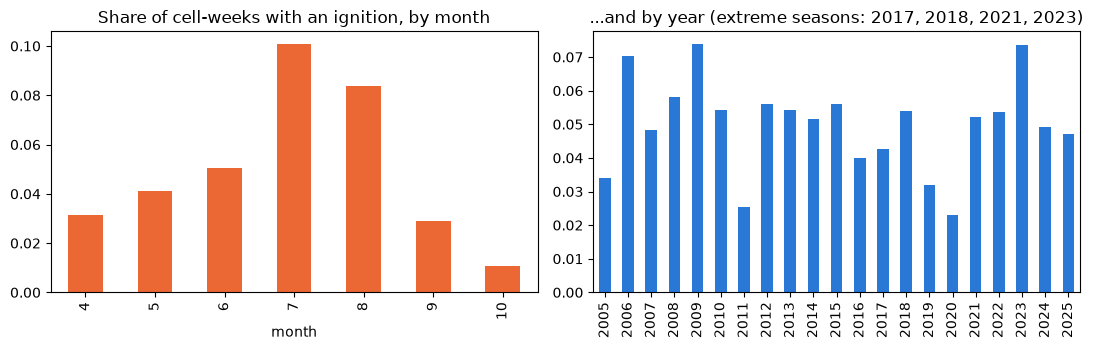

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.groupby(df.date.dt.month).label.mean().plot.bar(ax=ax[0], color="#eb6834"); ax[0].set(title="Share of cell-weeks with an ignition, by month", xlabel="month")
df.groupby("year").label.mean().plot.bar(ax=ax[1], color="#2a78d6"); ax[1].set(title="...and by year (extreme seasons: 2017, 2018, 2021, 2023)", xlabel="")
plt.tight_layout()

## 2. Features

Every feature at date *t* uses information up to and including *t*; the label covers days *t+1 … t+7* (unit tests enforce this).
Groups: raw **weather** (temperature, humidity from dew point, VPD, wind, rolling rainfall, days since rain), the **Canadian Fire Weather Index
System** codes (FFMC, DMC, DC, ISI, BUI, FWI, implemented from Van Wagner 1987 and validated against the published reference values),
**location/terrain**, **seasonality**, **recent ignitions** (this cell, neighbours), and a **local ignition history** rate (leave-one-year-out so training rows never see their own year).

In [3]:
for g, fs in FEATURE_GROUPS.items():
    print(f"{g:26s} {', '.join(fs)}")
df[[f for fs in FEATURE_GROUPS.values() for f in fs]].describe().T[["mean", "std", "min", "max"]].round(2)

Weather                    tmax, rh, vpd, wind_kmh, precip, precip_7d, precip_30d, days_since_rain, tmax_7d, rh_min_7d
Fire Weather Index codes   ffmc, dmc, dc, isi, bui, fwi
Neighbourhood & trend      nbr_fwi, nbr_dc, fwi_max_7d, fwi_chg_7d, tmax_max_7d, wind_max_7d
Location / terrain / access lat, lon, elevation, road_log
Seasonality                doy_sin, doy_cos
Recent ignitions           ign_cell_7d, ign_cell_30d, ign_nbr_30d
Local ignition history     rate_cell_month, rate_cell


,mean,std,min,max
tmax,11.35,7.78,-19.91,36.88
rh,61.55,15.55,11.41,99.86
vpd,6.50,5.54,0.01,49.15
wind_kmh,11.59,6.82,2.12,90.76
precip,2.93,4.85,0.00,108.42
precip_7d,20.04,19.96,0.00,286.13
precip_30d,83.89,57.94,1.01,784.84
days_since_rain,1.79,3.17,0.00,60.00
tmax_7d,11.34,7.29,-16.63,38.01
rh_min_7d,50.76,13.75,10.59,97.15


## 3. Does the model beat 'it's July in the interior'?

The fair baseline is **climatology**: the historical ignition rate for that cell and month. It already knows where and when fires usually happen.

In [4]:
m = json.load(open(cfg.path("reports_dir") / "metrics.json"))
t = pd.DataFrame(m["test"])[["roc_auc", "pr_auc", "brier_skill", "ece", "capture_top5", "lift_top5"]]
t.round(3)

,roc_auc,pr_auc,brier_skill,ece,capture_top5,lift_top5
Climatology,0.861,0.281,0.142,0.005,0.311,6.226
Logistic regression,0.878,0.315,0.160,0.005,0.341,6.815
Random forest,0.886,0.324,0.174,0.003,0.346,6.925
Gradient boosting,0.887,0.322,0.170,0.006,0.346,6.929
Gradient boosting (calibrated),0.886,0.302,0.152,0.018,0.344,6.880
Random forest (calibrated),0.886,0.308,0.154,0.018,0.344,6.872
Logistic regression (calibrated),0.877,0.305,0.134,0.022,0.333,6.659


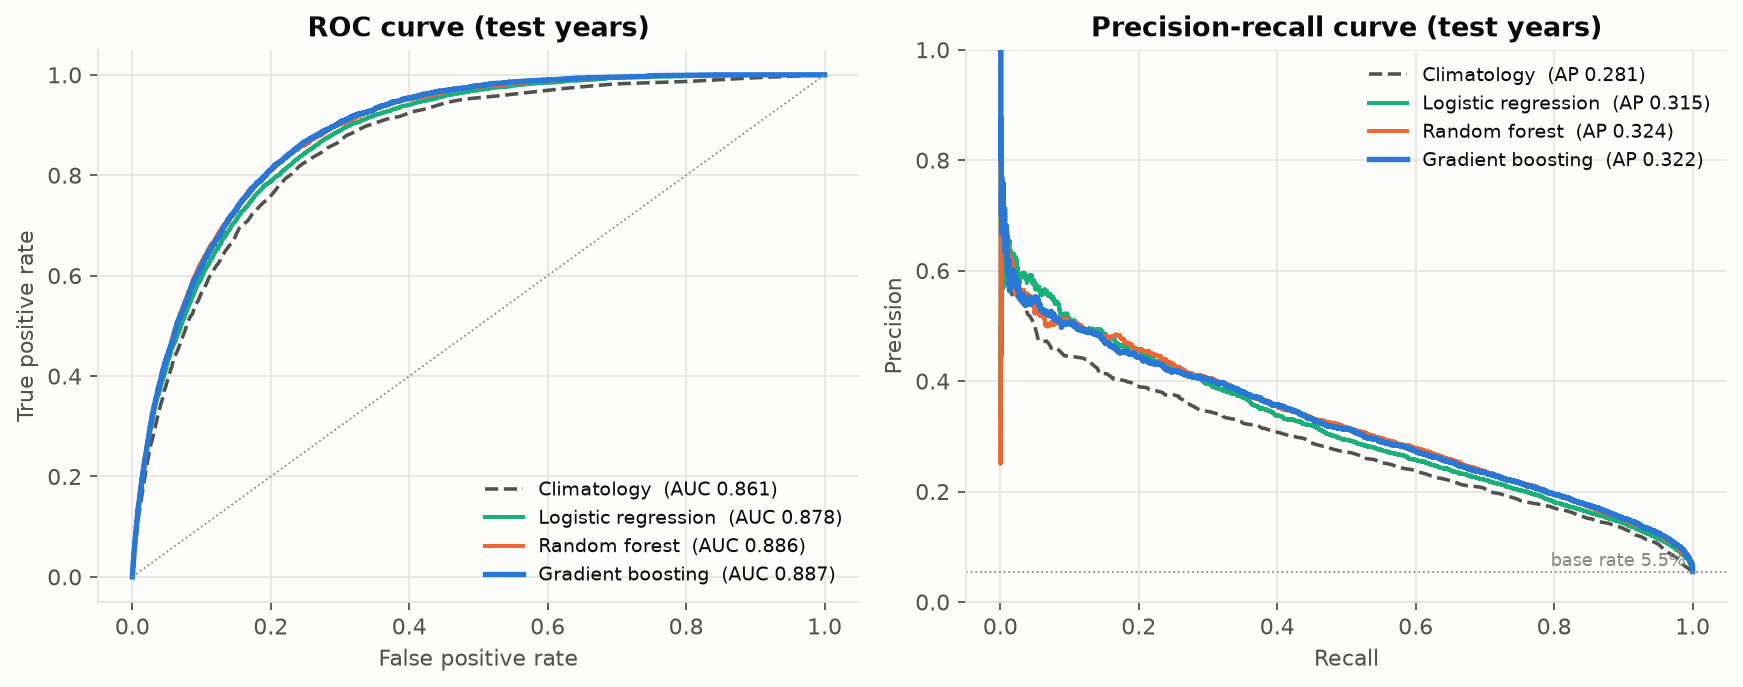

In [5]:
display(Image(str(cfg.path("reports_dir", "figures", "model_comparison.png"))))

**Reading this honestly.** Climatology is strong (ROC-AUC 0.86). The weather-aware models improve on it by a small but statistically clear margin (bootstrap intervals below). Most of the predictive power is *where and when*; weather adds the week-to-week signal.

In [6]:
b = pd.DataFrame(**m["bootstrap"])
b[b.metric.str.contains("- ref")].round(3)

,model,metric,mean,lo,hi
4,Logistic regression,roc_auc - ref,0.017,0.010,0.024
5,Logistic regression,pr_auc - ref,0.035,0.020,0.050
8,Random forest,roc_auc - ref,0.026,0.019,0.033
9,Random forest,pr_auc - ref,0.044,0.025,0.060
12,Gradient boosting,roc_auc - ref,0.026,0.020,0.033
13,Gradient boosting,pr_auc - ref,0.041,0.020,0.062


## 4. What does each feature group add?

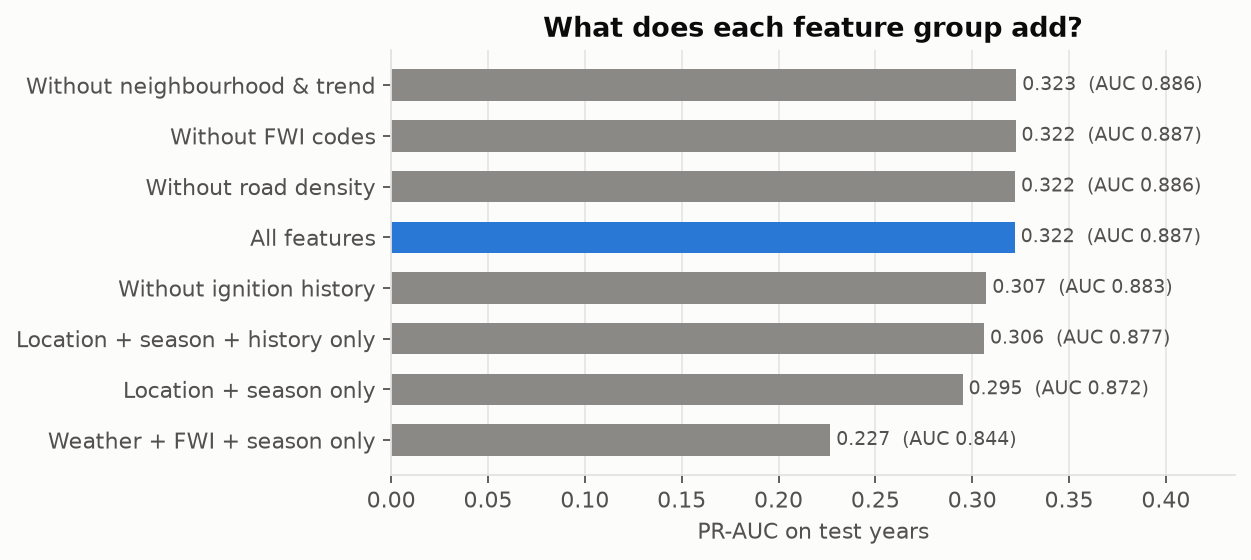

In [7]:
display(Image(str(cfg.path("reports_dir", "figures", "ablation.png"))))

Dropping the FWI codes, road density or the neighbourhood/trend features costs almost nothing for the any-ignition target (the raw weather carries the same information), but removing *all* weather and FWI features does cost skill. The big missing ingredient is almost certainly **lightning** (the dominant natural ignition cause in BC); it is not in the data here.

## 5. What drives individual predictions? (SHAP)

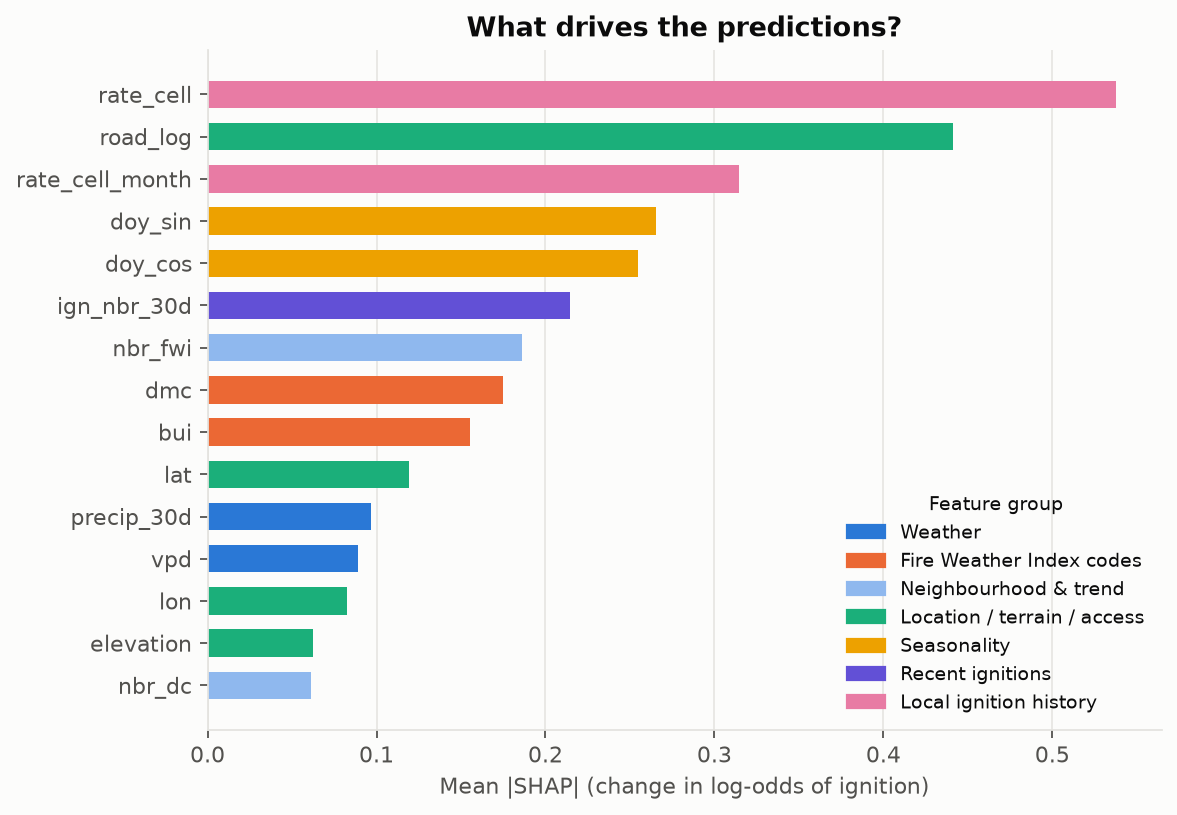

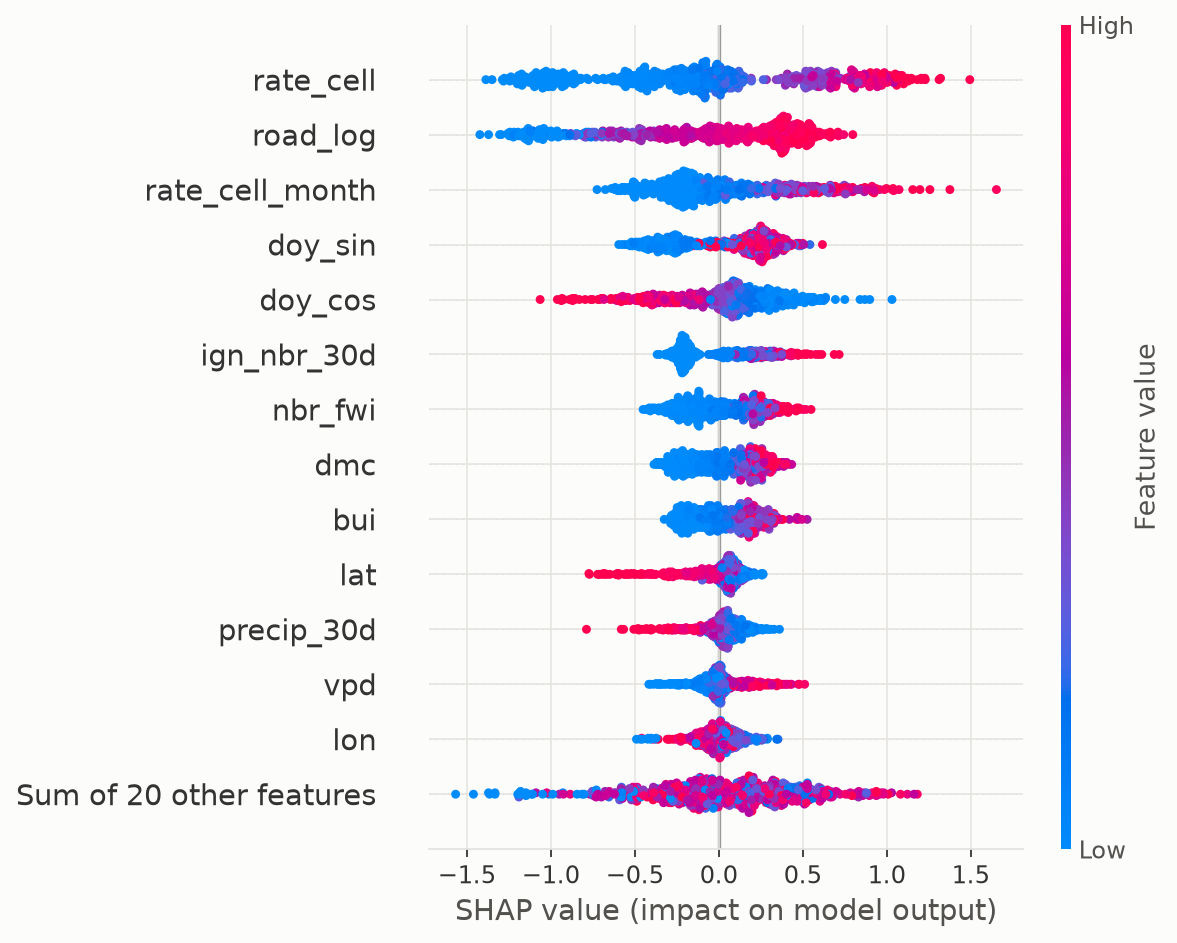

In [8]:
display(Image(str(cfg.path("reports_dir", "figures", "shap_importance.png"))))
display(Image(str(cfg.path("reports_dir", "figures", "shap_beeswarm.png"))))

## 6. Generalisation checks

Spatial-block CV (hold out 2°x2° blocks; local-history features removed):


roc_auc        pr_auc        brier_skill       
                                  mean    std   mean    std        mean    std
model                                                                         
Climatology (no local history)   0.673  0.021  0.081  0.033      -0.000  0.022
Gradient boosting                0.893  0.021  0.323  0.067       0.173  0.036

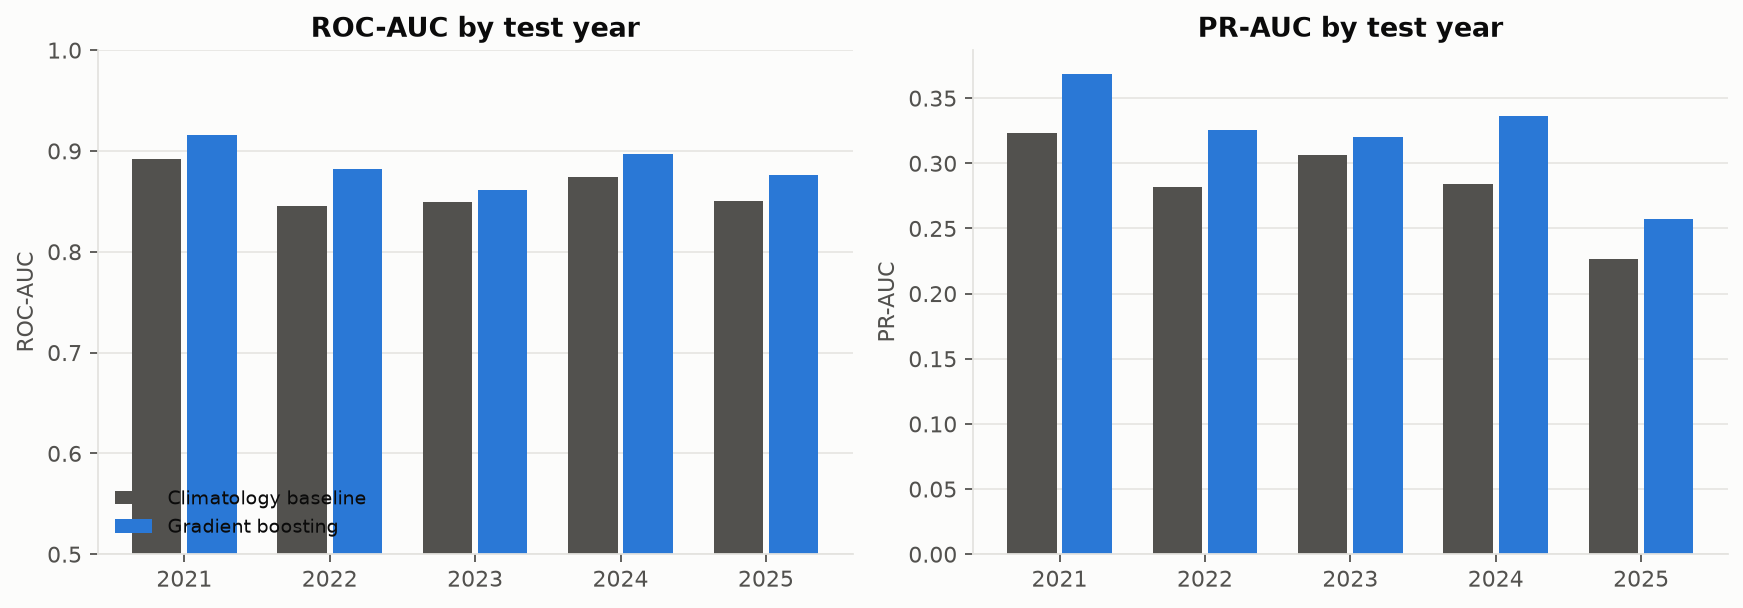

In [9]:
sp = pd.DataFrame(**m["spatial_cv"])
print("Spatial-block CV (hold out 2°x2° blocks; local-history features removed):")
display(sp.groupby("model")[["roc_auc", "pr_auc", "brier_skill"]].agg(["mean", "std"]).round(3))
display(Image(str(cfg.path("reports_dir", "figures", "per_year.png"))))

## 7. Calibration, and a negative result

Isotonic recalibration on the 2019–20 validation years made the model *worse* on the test years: those validation years were quiet, the test years were not. The raw model was already well calibrated, so it is the one deployed.

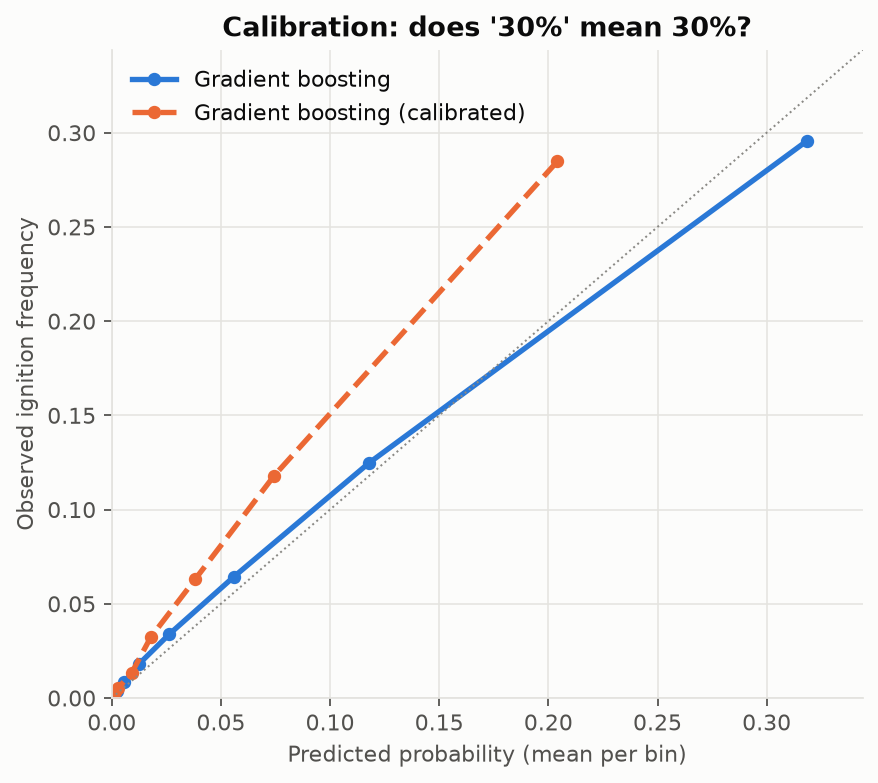

In [10]:
display(Image(str(cfg.path("reports_dir", "figures", "calibration.png"))))

## 8. Four targets, four sets of drivers

The same pipeline predicts any ignition, large fires (≥ 10 ha), lightning-caused and person-caused ignitions. Each target gets its own local-history rates, so a lightning-prone cell is not assumed to be person-caused-prone.

In [11]:
tj = json.load(open(cfg.path("reports_dir") / "targets.json"))
rows = []
for key, e in tj["targets"].items():
    for model in ("Climatology", "Gradient boosting"):
        m_ = {k: v[model] for k, v in e["test"].items()}
        rows.append({"target": e["description"], "model": model, "base rate": m_["prevalence"],
                     "ROC-AUC": m_["roc_auc"], "PR-AUC": m_["pr_auc"], "Brier skill": m_["brier_skill"]})
pd.DataFrame(rows).round(3)

,target,model,base rate,ROC-AUC,PR-AUC,Brier skill
0,any ignition,Climatology,0.055,0.861,0.281,0.142
1,any ignition,Gradient boosting,0.055,0.887,0.322,0.170
2,large fire (>= 10 ha),Climatology,0.010,0.788,0.047,0.019
3,large fire (>= 10 ha),Gradient boosting,0.010,0.855,0.062,0.021
4,lightning-caused ignition,Climatology,0.032,0.885,0.234,0.126
5,lightning-caused ignition,Gradient boosting,0.032,0.914,0.275,0.156
6,person-caused ignition,Climatology,0.024,0.871,0.177,0.093
7,person-caused ignition,Gradient boosting,0.024,0.906,0.204,0.109


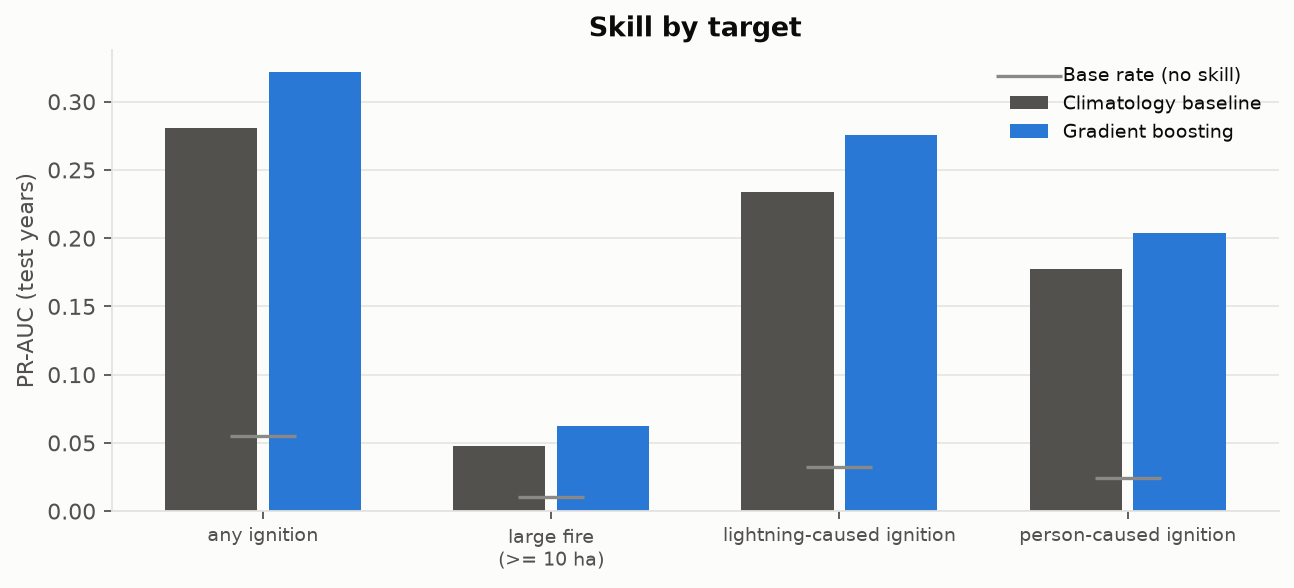

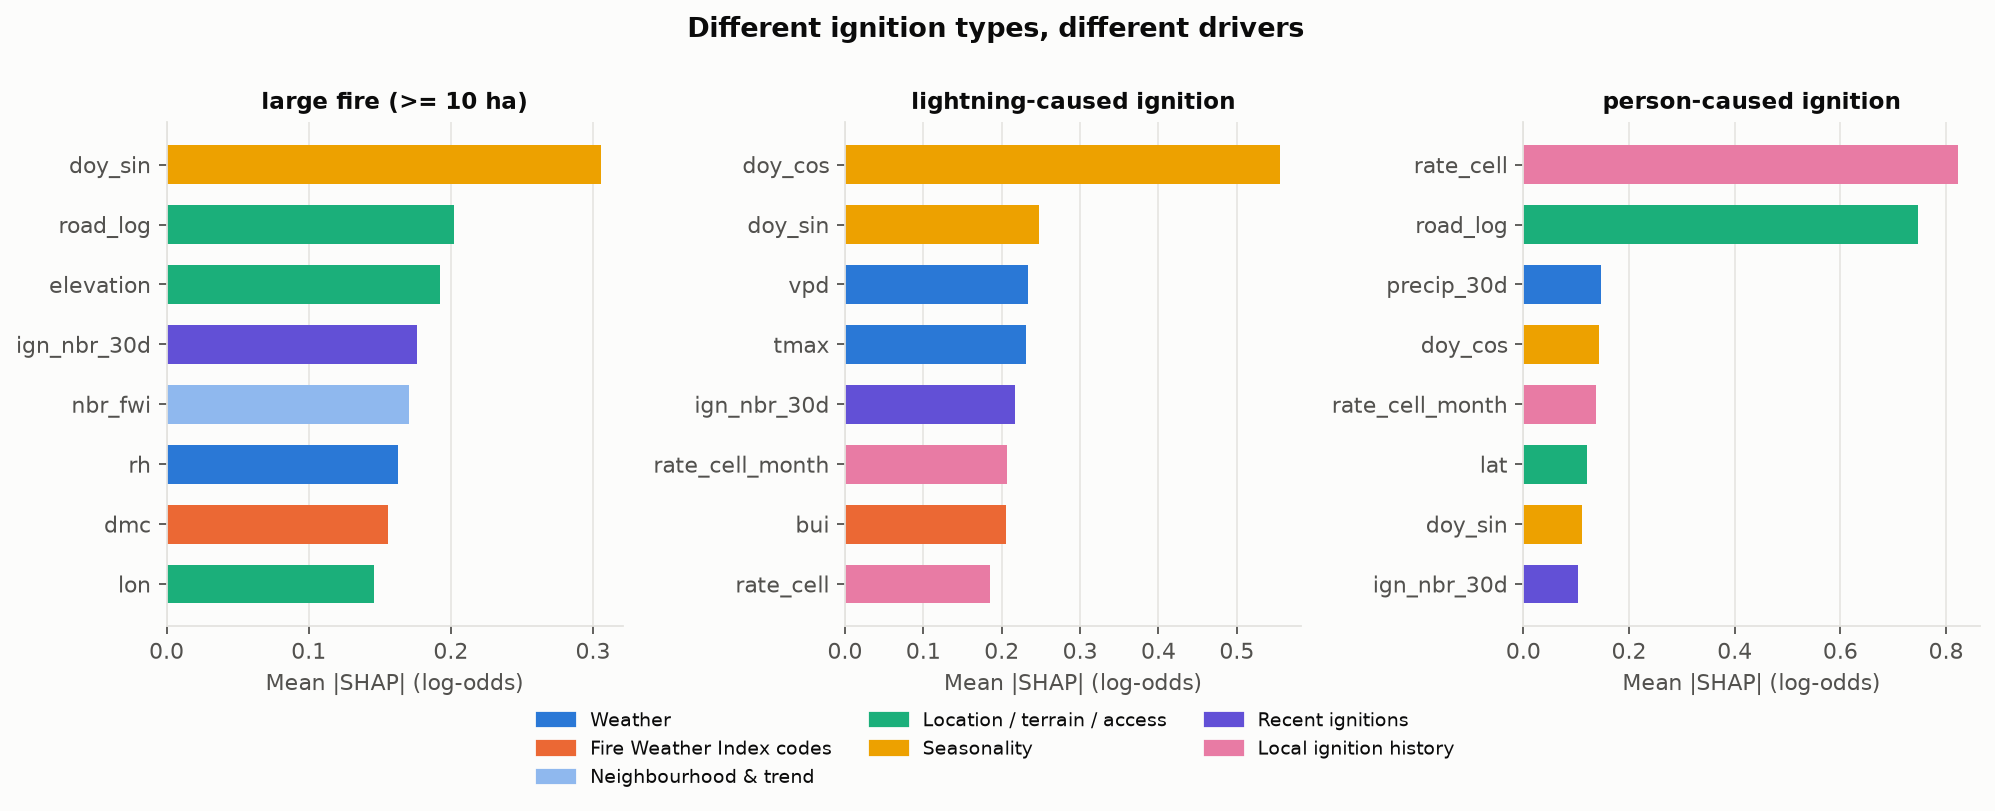

In [12]:
display(Image(str(cfg.path("reports_dir", "figures", "targets_summary.png"))))
display(Image(str(cfg.path("reports_dir", "figures", "target_drivers.png"))))

By SHAP importance, person-caused ignitions lean on **road access** and local history; lightning-caused ones on season, vapour-pressure deficit and temperature. SHAP shows what the model *uses*, not what it *gains*: re-training without road density and the neighbourhood/trend features (fixed iteration count, table below) changes every target's ROC-AUC by ≤ 0.005. They are redundant with local ignition history, so they are kept for interpretation, not accuracy.

In [13]:
pd.DataFrame({e["description"]: {f"{k} {m}": round(v, 4) for k, d in e["new_features"].items() for m, v in d.items()}
              for e in tj["targets"].values() if "new_features" in e}).T[
    ["without roc_auc", "with roc_auc", "without pr_auc", "with pr_auc", "without log_loss", "with log_loss"]]

,without roc_auc,with roc_auc,without pr_auc,with pr_auc,without log_loss,with log_loss
any ignition,0.8861,0.8868,0.3232,0.3220,0.1530,0.1528
large fire (>= 10 ha),0.8504,0.8547,0.0604,0.0622,0.0487,0.0484
lightning-caused ignition,0.9147,0.9139,0.2817,0.2754,0.0976,0.0980
person-caused ignition,0.9050,0.9060,0.2040,0.2040,0.0822,0.0820


## 9. When vs where: what the model actually adds

The pooled ranking metrics reward knowing *which weeks* are active. Two more honest views:

1. **Temporal skill**: does the model track the number of ignition cells per week across the province?
2. **Within-week ranking**: if crews can watch only K cells in a given week, how many ignitions are covered?

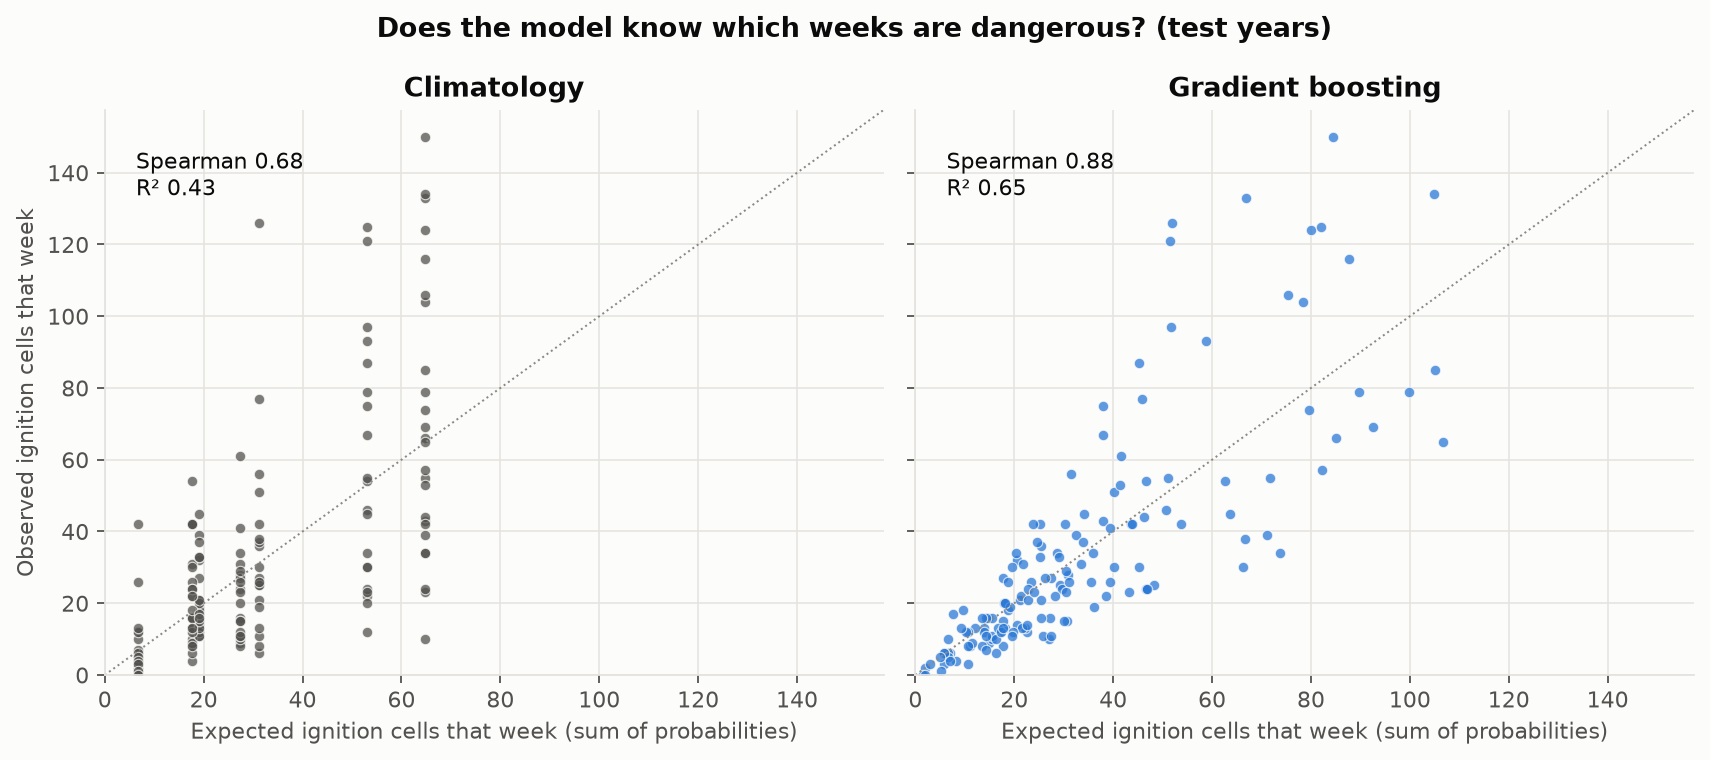

,Climatology,Gradient boosting
Spearman of weekly totals,,
label,0.68,0.88
label_large,0.56,0.69
label_lightning,0.79,0.90
label_person,0.34,0.69


In [14]:
display(Image(str(cfg.path("reports_dir", "figures", "temporal_skill.png"))))
ts = json.load(open(cfg.path("reports_dir") / "temporal_skill.json"))
pd.DataFrame({t: {m: v["spearman"] for m, v in d.items()} for t, d in ts.items()}).T.round(2).rename_axis("Spearman of weekly totals")

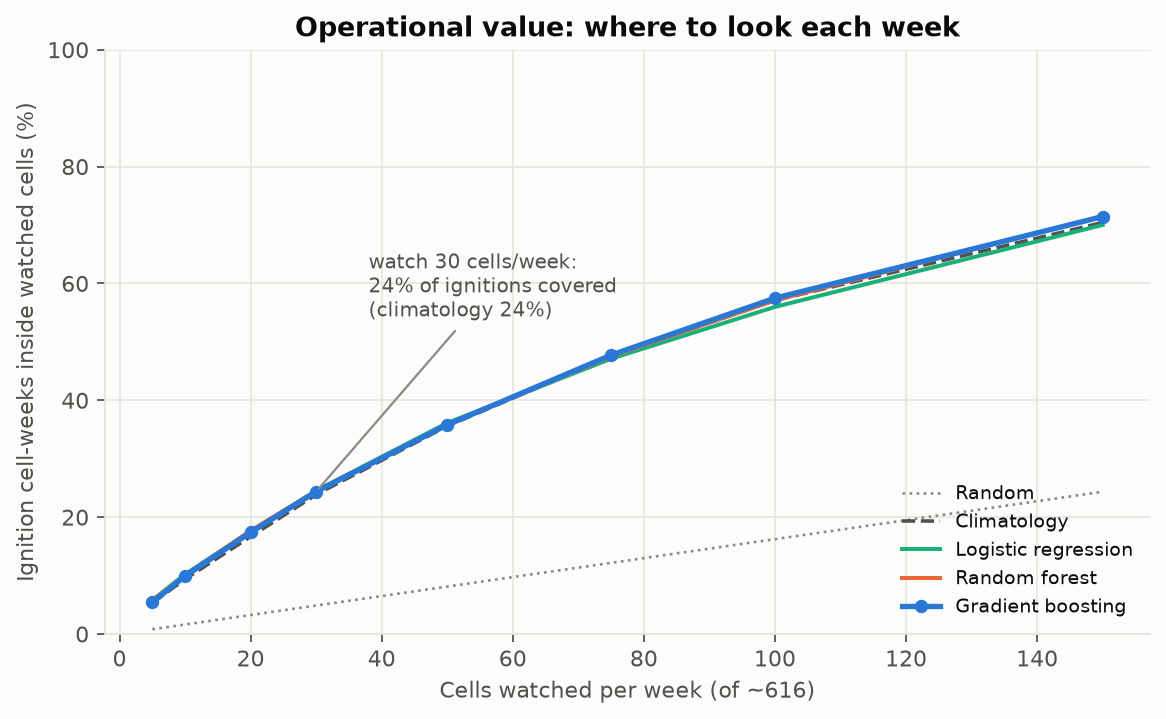

,Climatology,Logistic regression,Random forest,Gradient boosting,Random
5,0.053,0.058,0.057,0.054,0.008
10,0.094,0.102,0.100,0.099,0.016
20,0.167,0.176,0.177,0.174,0.032
30,0.239,0.245,0.245,0.244,0.049
50,0.356,0.361,0.359,0.358,0.081
75,0.475,0.471,0.475,0.477,0.122
100,0.571,0.560,0.571,0.575,0.162
150,0.704,0.700,0.716,0.714,0.244


In [15]:
display(Image(str(cfg.path("reports_dir", "figures", "weekly_capture.png"))))
pd.DataFrame(**m["weekly_capture"]).round(3)

**Takeaway.** The model is clearly better than climatology at *timing* (which weeks are dangerous) and no better at ranking cells *within* a week, except for person-caused ignitions.
Better spatial ranking needs information the model does not have: lightning strikes, fuel condition, local weather.

## 10. Hyperparameters barely matter

In [16]:
tu = pd.read_json(cfg.path("reports_dir") / "tuning.json")
print(f"validation log-loss across {len(tu)} configurations: {tu.val_logloss.min():.4f} .. {tu.val_logloss.max():.4f}")
tu.head(6).round(4)

validation log-loss across 14 configurations: 0.1345 .. 0.1356


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,val_logloss,val_pr_auc,mean_best_iter,seconds
0,0.03,63,200,1,0.5,0.1345,0.3140,294.3333,61
1,0.03,63,200,1,0.8,0.1347,0.3127,351.0000,73
2,0.03,31,50,5,1.0,0.1348,0.3112,320.6667,40
3,0.03,63,400,1,0.8,0.1349,0.3122,209.3333,61
4,0.05,31,100,5,0.8,0.1351,0.3103,285.6667,55
5,0.08,63,200,20,1.0,0.1351,0.3103,115.3333,64


## 11. Calibration, and a negative result

Isotonic recalibration on the 2019–20 validation years made the model *worse* on the test years: those validation years were quiet, the test years were not. The raw model was already well calibrated, so it is the one deployed.

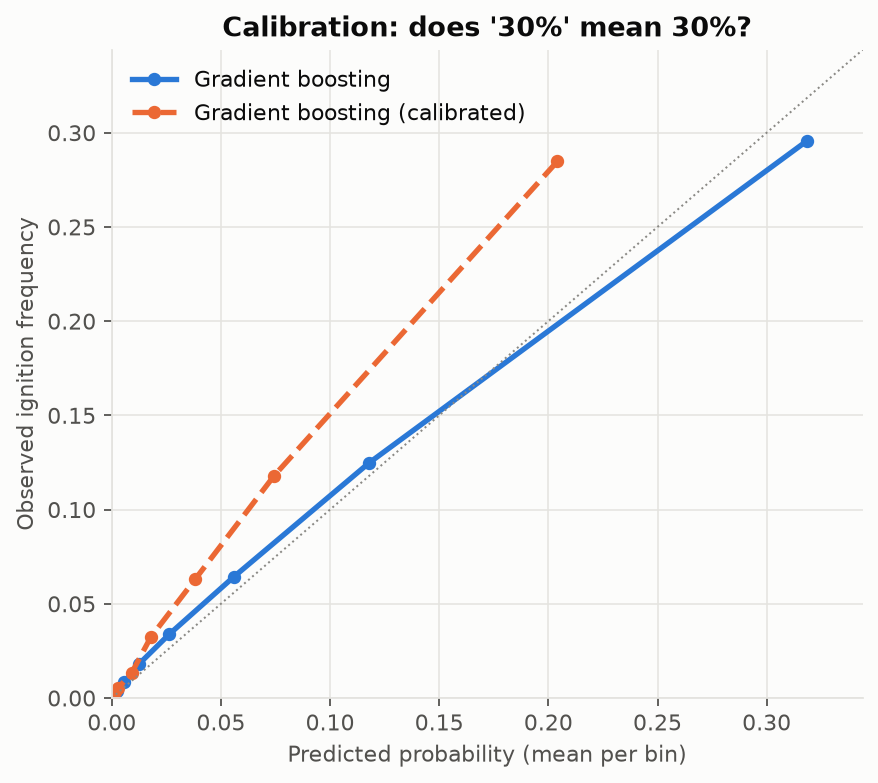

In [17]:
display(Image(str(cfg.path("reports_dir", "figures", "calibration.png"))))

## 12. A held-out week on the map

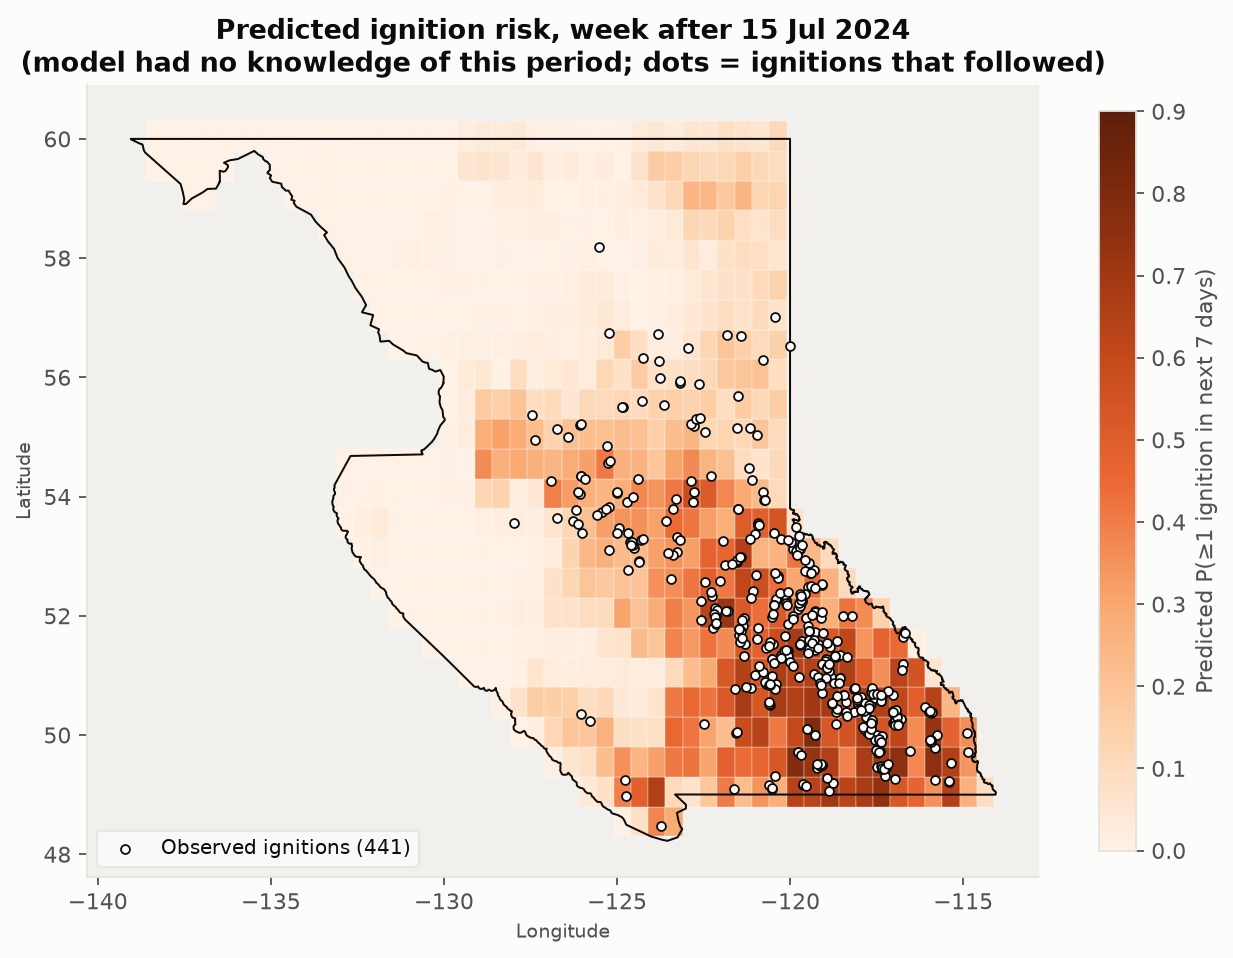

In [18]:
display(Image(str(cfg.path("reports_dir", "figures", "risk_map_peak_week.png"))))